In [1]:
# Cell 1: Import libraries and load FinBERT model
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import warnings
warnings.filterwarnings('ignore')

print(" Libraries imported!")
print(f" PyTorch version: {torch.__version__}")
print(f" Transformers library ready!")

print("\n Loading FinBERT model...")
print("   (This will download ~500MB on first run - be patient!)")

# Load FinBERT (pre-trained on financial text)
model_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

print(" FinBERT model loaded successfully!")
print("\n Model Details:")
print(f"   Name: {model_name}")
print(f"   Type: BERT transformer fine-tuned on financial text")
print(f"   Classes: Positive, Negative, Neutral")
print(f"   Parameters: ~110 million")

/Users/ryankhurana/Desktop/Financial_Sentiment_Trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 Libraries imported!
 PyTorch version: 2.14.1
 Transformers library ready!

 Loading FinBERT model...
   (This will download ~500MB on first run - be patient!)


W1108 01:22:11.925000 76760 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5022.49it/s]

 FinBERT model loaded successfully!

 Model Details:
   Name: ProsusAI/finbert
   Type: BERT transformer fine-tuned on financial text
   Classes: Positive, Negative, Neutral
   Parameters: ~110 million


In [2]:
# Cell 2: Test FinBERT sentiment analysis
print("\n TESTING FINBERT ON SAMPLE HEADLINES")
print("="*60)

# Sample financial headlines
test_headlines = [
    "Apple reports record quarterly earnings, beats expectations",
    "Tesla stock plunges on disappointing delivery numbers",
    "JPMorgan maintains neutral outlook for next quarter",
    "Amazon announces massive layoffs, stock drops",
    "Microsoft AI breakthrough drives stock surge"
]

def get_sentiment(text):
    """Get sentiment using FinBERT"""
    # Tokenize
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512)
    
    # Get model predictions
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Get probabilities
    probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
    
    # Labels: 0=Positive, 1=Negative, 2=Neutral
    sentiment_labels = ['Positive', 'Negative', 'Neutral']
    sentiment_idx = torch.argmax(probs).item()
    sentiment = sentiment_labels[sentiment_idx]
    confidence = probs[0][sentiment_idx].item()
    
    return {
        'sentiment': sentiment,
        'confidence': confidence,
        'positive_prob': probs[0][0].item(),
        'negative_prob': probs[0][1].item(),
        'neutral_prob': probs[0][2].item()
    }

# Test on sample headlines
print("\n Analyzing sample headlines:\n")
for headline in test_headlines:
    result = get_sentiment(headline)
    print(f"Headline: {headline}")
    print(f"   Sentiment: {result['sentiment']} (confidence: {result['confidence']:.2%})")
    print(f"   Probs → Pos: {result['positive_prob']:.2%}, Neg: {result['negative_prob']:.2%}, Neu: {result['neutral_prob']:.2%}\n")

print(" FinBERT is working correctly!")


 TESTING FINBERT ON SAMPLE HEADLINES

 Analyzing sample headlines:



Headline: Apple reports record quarterly earnings, beats expectations
   Sentiment: Positive (confidence: 89.92%)
   Probs → Pos: 89.92%, Neg: 4.41%, Neu: 5.66%

Headline: Tesla stock plunges on disappointing delivery numbers
   Sentiment: Negative (confidence: 96.17%)
   Probs → Pos: 0.93%, Neg: 96.17%, Neu: 2.90%

Headline: JPMorgan maintains neutral outlook for next quarter
   Sentiment: Neutral (confidence: 85.83%)
   Probs → Pos: 3.98%, Neg: 10.19%, Neu: 85.83%

Headline: Amazon announces massive layoffs, stock drops
   Sentiment: Negative (confidence: 94.74%)
   Probs → Pos: 0.91%, Neg: 94.74%, Neu: 4.35%

Headline: Microsoft AI breakthrough drives stock surge
   Sentiment: Negative (confidence: 72.18%)
   Probs → Pos: 8.57%, Neg: 72.18%, Neu: 19.25%

 FinBERT is working correctly!


In [3]:

print("\nLOADING NEWS DATA & ANALYZING SENTIMENT")
print("=" * 60)

stocks = ['AAPL', 'TSLA', 'JPM', 'AMZN', 'MSFT']

news_with_sentiment = {}

# Set model to evaluation mode
model.eval()

for ticker in stocks:
    print(f"\nProcessing {ticker}...")

    try:
        # Load news data
        news_df = pd.read_csv(f'./data/news_{ticker}.csv')

        if news_df.empty:
            print(f"   No news data found for {ticker}")
            continue

        # Derive a 'date' column from the 'publishedAt' timestamp
        if 'date' not in news_df.columns and 'publishedAt' in news_df.columns:
            news_df['date'] = pd.to_datetime(news_df['publishedAt'], errors='coerce').dt.date

        print(f"   Found {len(news_df)} articles")
        print("   Analyzing sentiment with FinBERT...")

        sentiments = []

        # Disable gradient calculations during inference
        with torch.inference_mode():

            for idx, row in news_df.iterrows():

                # Combine title and description safely
                title = str(row.get('title', '') or '')
                description = str(row.get('description', '') or '')

                # Handle missing values
                if pd.isna(row.get('title')):
                    title = ''

                if pd.isna(row.get('description')):
                    description = ''

                text = f"{title} {description}".strip()

                # Get sentiment
                result = get_sentiment(text)
                sentiments.append(result)

                # Progress indicator
                if (idx + 1) % 10 == 0:
                    print(f"      Processed {idx + 1}/{len(news_df)} articles...")

        # Add sentiment columns
        news_df['sentiment'] = [s['sentiment'] for s in sentiments]
        news_df['sentiment_confidence'] = [s['confidence'] for s in sentiments]

        news_df['positive_prob'] = [s['positive_prob'] for s in sentiments]
        news_df['negative_prob'] = [s['negative_prob'] for s in sentiments]
        news_df['neutral_prob'] = [s['neutral_prob'] for s in sentiments]

        # Sentiment score: range -1 to +1
        news_df['sentiment_score'] = (
            news_df['positive_prob'] - news_df['negative_prob']
        )

        # Store results
        news_with_sentiment[ticker] = news_df

        print("   Sentiment analysis complete!")
        print("   Sentiment distribution:")
        print(news_df['sentiment'].value_counts())

    except FileNotFoundError:
        print(f"   No news file found for {ticker}")
        continue

    except Exception as e:
        print(f"   Error processing {ticker}: {e}")
        continue

print("\nAll sentiment analysis complete!")

# Display sample results
if news_with_sentiment:

    sample_ticker = next(iter(news_with_sentiment))

    print(f"\nSample results for {sample_ticker}:")

    print(
        news_with_sentiment[sample_ticker][
            ['date', 'title', 'sentiment', 'sentiment_score']
        ].head()
    )



LOADING NEWS DATA & ANALYZING SENTIMENT

Processing AAPL...
   Found 96 articles
   Analyzing sentiment with FinBERT...


      Processed 10/96 articles...


      Processed 20/96 articles...


      Processed 30/96 articles...


      Processed 40/96 articles...


      Processed 50/96 articles...


... (40 outputs left out)

      Processed 70/100 articles...


      Processed 80/100 articles...


      Processed 90/100 articles...


      Processed 100/100 articles...
   Sentiment analysis complete!
   Sentiment distribution:
sentiment
Neutral     76
Positive    14
Negative    10
Name: count, dtype: int64

All sentiment analysis complete!

Sample results for AAPL:
         date                                              title sentiment  \
0  2026-10-07  Amazon Prime Day 2026 — 60+ of the best tech d...   Neutral   
1  2026-10-07  Microsoft, Nvidia CEOs to unveil new AI laptop...   Neutral   
2  2026-10-07  Unfolded iPhone Duo Lets You Preview Documents...   Neutral   
3  2026-10-07  Green Bay East boys basketball coach resigns a...  Negative   
4  2026-10-07  Apple and LG, The House For Everyone Else, Age...   Neutral   

   sentiment_score  
0         0.165715  
1         0.443903  
2         0.028647  
3        -0.791169  
4         0.154727  


In [4]:
print("\n AGGREGATING DAILY SENTIMENT SCORES")
print("="*60)

daily_sentiment = {}

for ticker in news_with_sentiment.keys():
    news_df = news_with_sentiment[ticker]
    
    # Group by date and aggregate
    daily = news_df.groupby('date').agg({
        'sentiment_score': ['mean', 'std', 'count'],
        'positive_prob': 'mean',
        'negative_prob': 'mean',
        'neutral_prob': 'mean'
    }).reset_index()
    
    # Flatten column names
    daily.columns = ['date', 'avg_sentiment', 'sentiment_std', 'news_count',
                     'avg_positive', 'avg_negative', 'avg_neutral']
    
    daily_sentiment[ticker] = daily
    
    print(f"\n{ticker}:")
    print(f"   {len(daily)} unique dates with news")
    print(f"   Average daily sentiment: {daily['avg_sentiment'].mean():.3f}")
    print(f"   Most positive day: {daily.loc[daily['avg_sentiment'].idxmax(), 'date']} ({daily['avg_sentiment'].max():.3f})")
    print(f"   Most negative day: {daily.loc[daily['avg_sentiment'].idxmin(), 'date']} ({daily['avg_sentiment'].min():.3f})")

# Save sentiment data
for ticker, df in daily_sentiment.items():
    filename = f'../data/{ticker}_daily_sentiment.csv'
    df.to_csv(filename, index=False)
    print(f"\n✅ Saved: {filename}")

print("\n✅ Daily sentiment aggregation complete!")


 AGGREGATING DAILY SENTIMENT SCORES

AAPL:
   1 unique dates with news
   Average daily sentiment: 0.031
   Most positive day: 2026-10-07 (0.031)
   Most negative day: 2026-10-07 (0.031)

TSLA:
   3 unique dates with news
   Average daily sentiment: 0.024
   Most positive day: 2026-10-06 (0.081)
   Most negative day: 2026-10-05 (-0.055)

JPM:
   9 unique dates with news
   Average daily sentiment: -0.036
   Most positive day: 2026-10-02 (0.290)
   Most negative day: 2026-09-29 (-0.573)

AMZN:
   1 unique dates with news
   Average daily sentiment: -0.036
   Most positive day: 2026-10-07 (-0.036)
   Most negative day: 2026-10-07 (-0.036)

MSFT:
   2 unique dates with news
   Average daily sentiment: 0.097
   Most positive day: 2026-10-06 (0.136)
   Most negative day: 2026-10-07 (0.058)

✅ Saved: ../data/AAPL_daily_sentiment.csv

✅ Saved: ../data/TSLA_daily_sentiment.csv

✅ Saved: ../data/JPM_daily_sentiment.csv

✅ Saved: ../data/AMZN_daily_sentiment.csv

✅ Saved: ../data/MSFT_daily_sen

✅ Saved: visualizations/finbert_sentiment_distribution.png


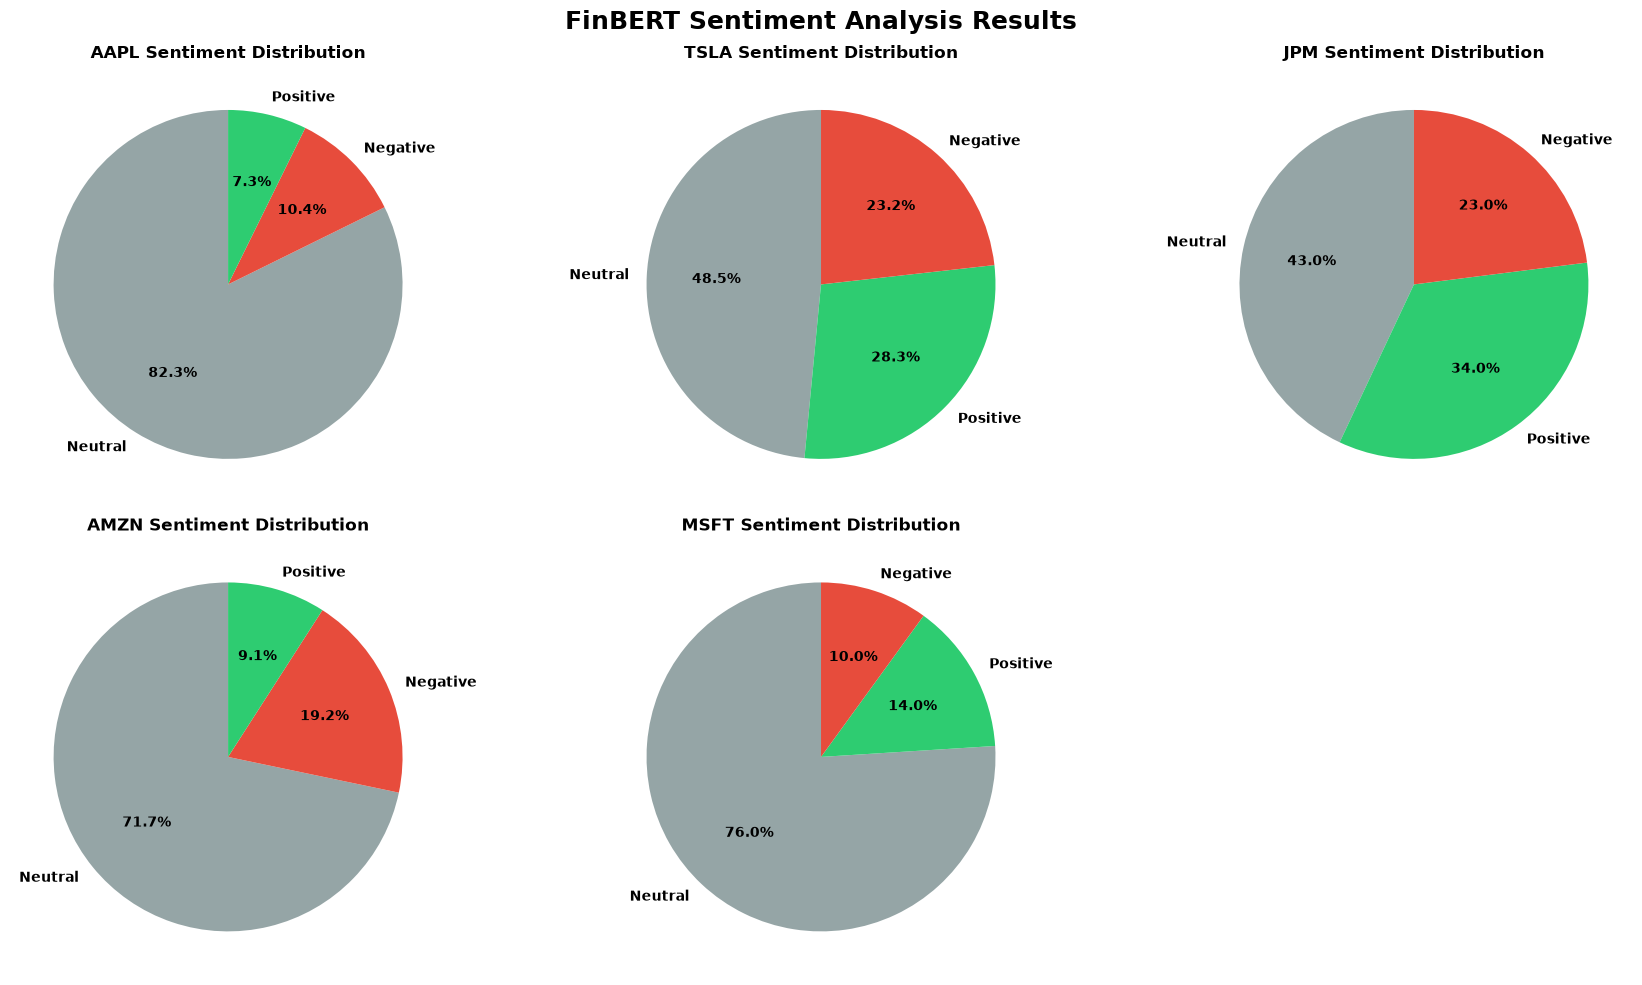

✅ Saved: visualizations/sentiment_score_distribution.png


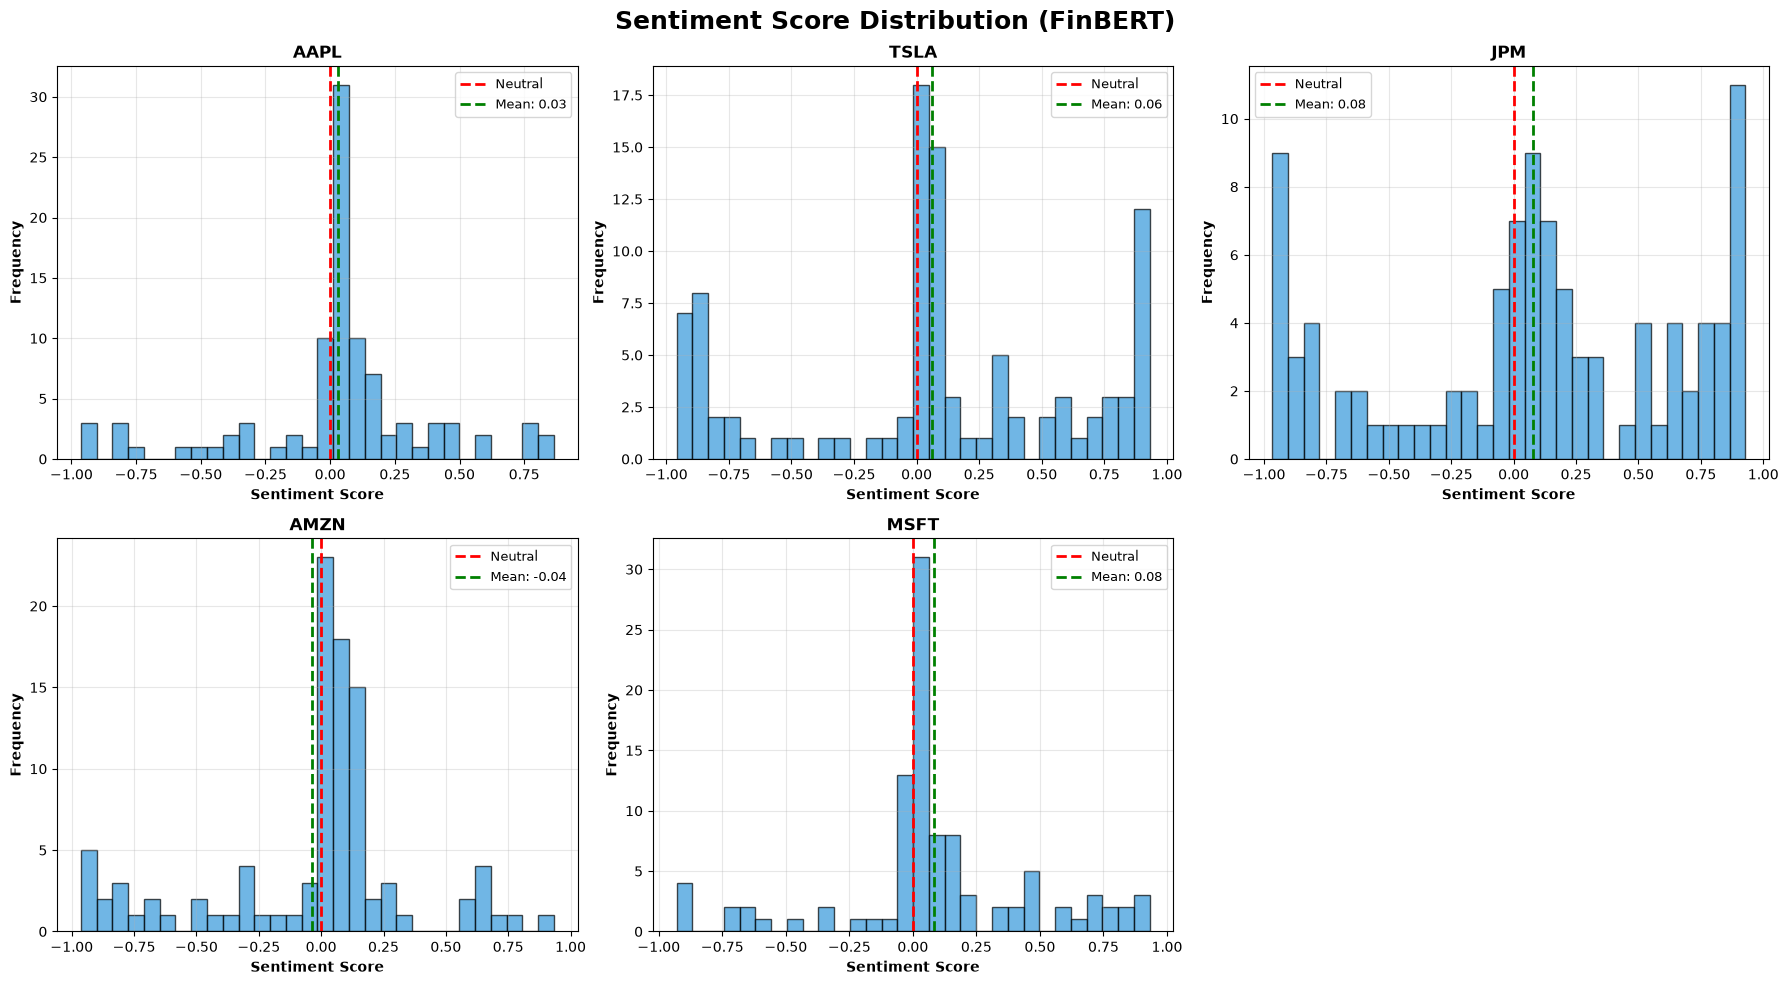

In [5]:
print("="*60)

import matplotlib.pyplot as plt
import seaborn as sns

# Overall sentiment distribution
if len(news_with_sentiment) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('FinBERT Sentiment Analysis Results', fontsize=18, fontweight='bold')
    
    for idx, ticker in enumerate(list(news_with_sentiment.keys())[:5]):
        row = idx // 3
        col = idx % 3
        ax = axes[row, col]
        
        news_df = news_with_sentiment[ticker]
        
        # Sentiment distribution pie chart
        sentiment_counts = news_df['sentiment'].value_counts()
        colors_sent = {'Positive': '#2ecc71', 'Negative': '#e74c3c', 'Neutral': '#95a5a6'}
        colors = [colors_sent.get(s, '#95a5a6') for s in sentiment_counts.index]
        
        ax.pie(sentiment_counts.values, labels=sentiment_counts.index, 
               colors=colors, autopct='%1.1f%%', startangle=90,
               textprops={'fontsize': 10, 'fontweight': 'bold'})
        ax.set_title(f'{ticker} Sentiment Distribution', fontsize=12, fontweight='bold')
    
    # Remove empty subplot
    if len(news_with_sentiment) < 6:
        fig.delaxes(axes[1, 2])
    
    plt.tight_layout()
    plt.savefig('../visualizations/finbert_sentiment_distribution.png', dpi=300, bbox_inches='tight')
    print("✅ Saved: visualizations/finbert_sentiment_distribution.png")
    plt.show()
    
    # Sentiment score distribution
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Sentiment Score Distribution (FinBERT)', fontsize=18, fontweight='bold')
    
    for idx, ticker in enumerate(list(news_with_sentiment.keys())[:5]):
        row = idx // 3
        col = idx % 3
        ax = axes[row, col]
        
        news_df = news_with_sentiment[ticker]
        
        # Histogram of sentiment scores
        ax.hist(news_df['sentiment_score'], bins=30, color='#3498db', 
                alpha=0.7, edgecolor='black')
        ax.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Neutral')
        ax.axvline(x=news_df['sentiment_score'].mean(), color='green', 
                   linestyle='--', linewidth=2, label=f'Mean: {news_df["sentiment_score"].mean():.2f}')
        ax.set_xlabel('Sentiment Score', fontsize=10, fontweight='bold')
        ax.set_ylabel('Frequency', fontsize=10, fontweight='bold')
        ax.set_title(f'{ticker}', fontsize=12, fontweight='bold')
        ax.legend(fontsize=9)
        ax.grid(alpha=0.3)
    
    if len(news_with_sentiment) < 6:
        fig.delaxes(axes[1, 2])
    
    plt.tight_layout()
    plt.savefig('../visualizations/sentiment_score_distribution.png', dpi=300, bbox_inches='tight')
    print("✅ Saved: visualizations/sentiment_score_distribution.png")
    plt.show()

else:
    print("⚠️ No sentiment data available for visualization")
    print("   This is okay - we can still proceed with price-based features!")
